# Caracterizacion de hardware en LocalScore (H0-H7)

Notebook para etiquetar y caracterizar corridas del dump de LocalScore por perfiles de hardware **H0-H7** (CPU edge/legacy hasta servidor institucional), usando un dataset a nivel corrida (`benchmark_runs`) y joins con catálogos (`benchmark_systems`, `accelerators`, `model_variants`, `models`, `runtimes`).

- Perfiles: `docs/caracterizacion-hardware-localscore.md`.
- Dataset base: `data/raw/localscore-09-24-2025.db` (mismo esquema que el notebook `exploracion_localscore.ipynb`).
- Salida: `data/processed/` con CSV/Parquet (si esta disponible).


In [1]:
import sqlite3
from pathlib import Path

import pandas as pd

DB_PATH = Path("../data/raw/localscore-09-24-2025.db")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not DB_PATH.exists():
    print(f"DB no encontrada en: {DB_PATH}")
    print("Coloca el archivo LocalScore dump en data/raw/ y ejecuta de nuevo.")
    raise FileNotFoundError(DB_PATH)

conn = sqlite3.connect(DB_PATH)
print("Conectado a:", DB_PATH)


Conectado a: ../data/raw/localscore-09-24-2025.db


In [2]:
# =========================
# Config de perfiles H0-H7
# =========================

# ── CPU (ram_gb del host, desde benchmark_systems) ───────────────────────────
# Cortes en potencias de 2 alineadas a módulos DIMM reales.
# Justificación: 4 GB es el mínimo para correr un LLM cuantizado (1B Q4);
#               8 y 16 GB son los umbrales de mercado más comunes.
CPU_H0_MAX_EXCL = 4    # [0, 4)   — H0: edge/legacy, no puede correr LLMs
CPU_H1_MIN = 4
CPU_H1_MAX_EXCL = 8    # [4, 8)   — H1: puede correr 1–4B Q4
CPU_H2_MIN = 8
CPU_H2_MAX_EXCL = 16   # [8, 16)  — H2: puede correr 7–8B Q4/Q8
CPU_H3_MIN = 16        # [16, ∞)  — H3: puede correr 13B+ o batch

# ── GPU (memory_gb del acelerador, desde accelerators) ───────────────────────
# Cortes en 8 GB y 24 GB coinciden con discontinuidades reales del mercado:
#   - No existen GPUs de consumo entre 16 y 24 GB (el salto RTX 4080→4090).
#   - 8 GB es la frontera entre poder correr 7B Q4 o no.
GPU_H4_MAX_EXCL = 8    # [0, 8)   — H4: GPU entrada, hasta 3–7B Q4
GPU_H5_MIN = 8
GPU_H5_MAX_EXCL = 24   # [8, 24)  — H5: GPU media, 7–13B cómodamente
GPU_H6_MIN = 24        # [24, ∞)  — H6: GPU high-end, 34B+ o sin restricción
# H7: datacenter/servidor — prioridad absoluta sobre VRAM (ver is_datacenter_gpu)

# ── Heurística datacenter para H7 ────────────────────────────────────────────
# Regla: si el nombre del acelerador contiene alguna keyword de datacenter
# => H7 independientemente de la VRAM (un A100 de 40 GB no es uso personal).
DATACENTER_KEYWORDS = [
    "H100", "H200", "A100", "A40", "L40S",
    "MI250", "MI300", "MI300X",
    "TESLA", "V100", "P100", "A800",
    "GAUDI", "GAUD",
    "SERVER EDITION", "BLACKWELL SERVER"
]

def is_datacenter_gpu(accelerator_name: str) -> bool:
    if accelerator_name is None or pd.isna(accelerator_name):
        return False
    name = str(accelerator_name).upper()
    return any(kw in name for kw in DATACENTER_KEYWORDS)

def label_h(row: pd.Series) -> str:
    atype = row.get("accelerator_type", None)
    atype = str(atype).upper() if atype is not None and not pd.isna(atype) else None

    if atype is None:
        return "UNKNOWN"

    # ── CPU-only ─────────────────────────────────────────────────────────────
    if atype == "CPU":
        ram = row.get("ram_gb", None)
        if ram is None or pd.isna(ram):
            return "UNKNOWN"
        ram = float(ram)
        if ram < CPU_H0_MAX_EXCL:
            return "H0_CPU_EDGE"
        if ram < CPU_H1_MAX_EXCL:
            return "H1_CPU_LOW"
        if ram < CPU_H2_MAX_EXCL:
            return "H2_CPU_MED"
        return "H3_CPU_HIGH"

    # ── GPU ──────────────────────────────────────────────────────────────────
    # Apple Silicon: LocalScore registra el mismo chip dos veces (type=GPU con
    # memory_gb = memoria unificada total, y type=CPU con la misma memory_gb).
    # Las corridas de inferencia usan Metal (type=GPU), por lo que caen en H4-H6.
    # LIMITACIÓN: la memoria unificada es el límite total del sistema (sin RAM extra).
    if atype == "GPU":
        name = row.get("accelerator_name", None)
        vram = row.get("memory_gb", None)

        # H7 tiene prioridad absoluta: datacenter/servidor
        if is_datacenter_gpu(name):
            return "H7_SERVER"

        if vram is None or pd.isna(vram):
            return "UNKNOWN"
        vram = float(vram)

        if vram >= GPU_H6_MIN:
            return "H6_GPU_HIGH"
        if vram >= GPU_H5_MIN:
            return "H5_GPU_MED"
        return "H4_GPU_LOW"

    return "UNKNOWN"

print("Perfiles H0-H7 configurados.")
print(f"  CPU: H0 <{CPU_H0_MAX_EXCL} GB | H1 [{CPU_H1_MIN},{CPU_H1_MAX_EXCL}) GB | H2 [{CPU_H2_MIN},{CPU_H2_MAX_EXCL}) GB | H3 >={CPU_H3_MIN} GB")
print(f"  GPU: H4 <{GPU_H4_MAX_EXCL} GB VRAM | H5 [{GPU_H5_MIN},{GPU_H5_MAX_EXCL}) GB | H6 >={GPU_H6_MIN} GB | H7 datacenter")


Perfiles H0-H7 configurados.
  CPU: H0 <4 GB | H1 [4,8) GB | H2 [8,16) GB | H3 >=16 GB
  GPU: H4 <8 GB VRAM | H5 [8,24) GB | H6 >=24 GB | H7 datacenter


In [3]:
# =========================
# Carga y joins (nivel corrida)
# =========================

query = """
SELECT
  br.id                           AS benchmark_run_id,
  br.id                           AS run_name,
  br.model_variant_id,
  br.runtime_id,
  br.system_id,
  br.accelerator_id,
  br.avg_prompt_tps,
  br.avg_gen_tps,
  br.avg_ttft_ms,
  br.performance_score,

  bs.cpu_name,
  bs.cpu_arch,
  bs.ram_gb,

  acc.name                        AS accelerator_name,
  acc.type                        AS accelerator_type,
  acc.memory_gb                   AS memory_gb,
  acc.manufacturer,

  mv.quantization,
  m.name                          AS model_name,
  m.params,

  r.name                          AS runtime_name
FROM benchmark_runs br
JOIN benchmark_systems bs
  ON br.system_id = bs.id
JOIN accelerators acc
  ON br.accelerator_id = acc.id
JOIN model_variants mv
  ON br.model_variant_id = mv.id
JOIN models m
  ON mv.model_id = m.id
JOIN runtimes r
  ON br.runtime_id = r.id
"""

runs = pd.read_sql_query(query, conn)
print("runs shape:", runs.shape)
display(runs.head(3))

# Normalizar tipos numericos por si vienen como string
for c in ["ram_gb", "memory_gb", "avg_prompt_tps", "avg_gen_tps", "avg_ttft_ms", "performance_score"]:
    if c in runs.columns:
        runs[c] = pd.to_numeric(runs[c], errors="coerce")


runs shape: (1556, 21)


,benchmark_run_id,run_name,model_variant_id,runtime_id,system_id,accelerator_id,avg_prompt_tps,avg_gen_tps,avg_ttft_ms,performance_score,...,cpu_arch,ram_gb,accelerator_name,accelerator_type,memory_gb,manufacturer,quantization,model_name,params,runtime_name
0,1,1,1,1,1,1,3552.260062,103.101197,357.877564,1007.731103,...,x86_64,125.64,NVIDIA GeForce RTX 3090,GPU,24.0,NVIDIA,Q4_K - Medium,Meta Llama 3.1 8B Instruct,8030263296,llamafile
1,2,2,2,1,1,1,2005.328495,59.943200,640.390159,572.567815,...,x86_64,125.64,NVIDIA GeForce RTX 3090,GPU,24.0,NVIDIA,Q4_K - Medium,Qwen2.5 14B Instruct,14770033664,llamafile
2,3,3,3,1,1,1,14061.091384,330.012790,94.525489,3661.566761,...,x86_64,125.64,NVIDIA GeForce RTX 3090,GPU,24.0,NVIDIA,Q4_K - Medium,Llama 3.2 1B Instruct,1498483200,llamafile


In [4]:
# =========================
# Etiquetado H1-H6
# =========================

runs["profile_h"] = runs.apply(label_h, axis=1)

print("Perfiles (conteo):")
print(runs["profile_h"].value_counts(dropna=False))

unknown_rate = (runs["profile_h"] == "UNKNOWN").mean() * 100.0
print(f"UNKNOWN rate: {unknown_rate:.2f}%")

display(runs[["benchmark_run_id","model_name","quantization","runtime_name","accelerator_type","ram_gb","memory_gb","profile_h"]].head(5))


Perfiles (conteo):
profile_h
H3_CPU_HIGH    440
H5_GPU_MED     440
H6_GPU_HIGH    375
H2_CPU_MED     129
H4_GPU_LOW      70
H1_CPU_LOW      51
H7_SERVER       45
H0_CPU_EDGE      6
Name: count, dtype: int64
UNKNOWN rate: 0.00%


,benchmark_run_id,model_name,quantization,runtime_name,accelerator_type,ram_gb,memory_gb,profile_h
0,1,Meta Llama 3.1 8B Instruct,Q4_K - Medium,llamafile,GPU,125.64,24.00,H6_GPU_HIGH
1,2,Qwen2.5 14B Instruct,Q4_K - Medium,llamafile,GPU,125.64,24.00,H6_GPU_HIGH
2,3,Llama 3.2 1B Instruct,Q4_K - Medium,llamafile,GPU,125.64,24.00,H6_GPU_HIGH
3,4,Llama 3.2 1B Instruct,Q4_K - Medium,llamafile,GPU,32.00,32.00,H6_GPU_HIGH
4,5,Llama 3.2 1B Instruct,Q4_K - Medium,llamafile,CPU,125.64,125.64,H3_CPU_HIGH


In [5]:
# =========================
# Cobertura y tablas
# =========================

coverage = (
    runs.groupby("profile_h")
    .agg(
        n_runs=("benchmark_run_id","count"),
        n_models=("model_name","nunique"),
        n_runtimes=("runtime_name","nunique"),
        n_accelerators=("accelerator_name","nunique"),
        n_cpu_arch=("cpu_arch","nunique"),
    )
    .reset_index()
    .sort_values("n_runs", ascending=False)
)

perf_summary = (
    runs.groupby("profile_h")
    .agg(
        ttft_ms_median=("avg_ttft_ms","median"),
        ttft_ms_mean=("avg_ttft_ms","mean"),
        gen_tps_median=("avg_gen_tps","median"),
        gen_tps_mean=("avg_gen_tps","mean"),
        score_medio=("performance_score","mean"),
    )
    .reset_index()
)

display(coverage)
display(perf_summary)


,profile_h,n_runs,n_models,n_runtimes,n_accelerators,n_cpu_arch
3,H3_CPU_HIGH,440,44,1,161,4
5,H5_GPU_MED,440,38,1,80,2
6,H6_GPU_HIGH,375,49,1,45,2
2,H2_CPU_MED,129,22,1,55,3
4,H4_GPU_LOW,70,23,1,19,2
1,H1_CPU_LOW,51,8,1,22,3
7,H7_SERVER,45,3,1,16,1
0,H0_CPU_EDGE,6,1,1,6,2


,profile_h,ttft_ms_median,ttft_ms_mean,gen_tps_median,gen_tps_mean,score_medio
0,H0_CPU_EDGE,185895.660159,688825.715464,2.458148,4.690172,9.491220
1,H1_CPU_LOW,43675.325775,78536.757829,8.962508,13.410486,30.395527
2,H2_CPU_MED,30434.071567,69739.865355,13.823986,16.400519,39.177715
3,H3_CPU_HIGH,14478.585783,45732.694706,15.137842,98.259534,252.306626
4,H4_GPU_LOW,1022.641443,2230.832003,46.166911,69.420014,687.697567
5,H5_GPU_MED,715.459545,1837.734616,50.427788,76.466721,824.745831
6,H6_GPU_HIGH,679.636556,2731.916855,59.419563,87.304532,920.320009
7,H7_SERVER,400.597807,633.744486,72.174766,105.093170,1390.869656


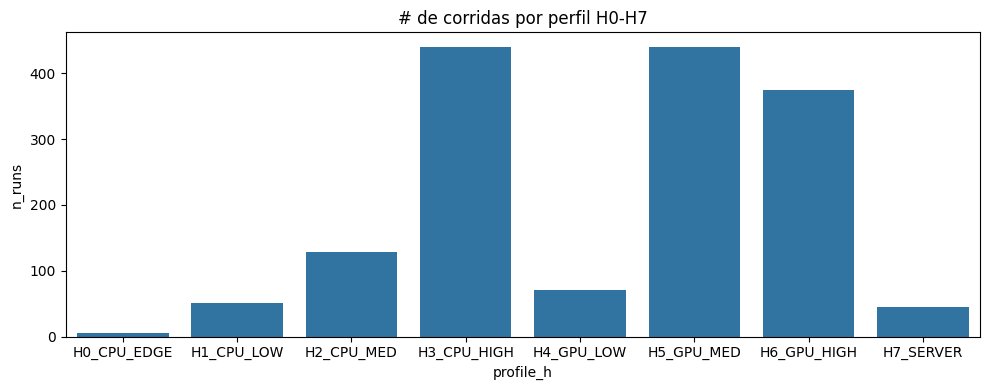

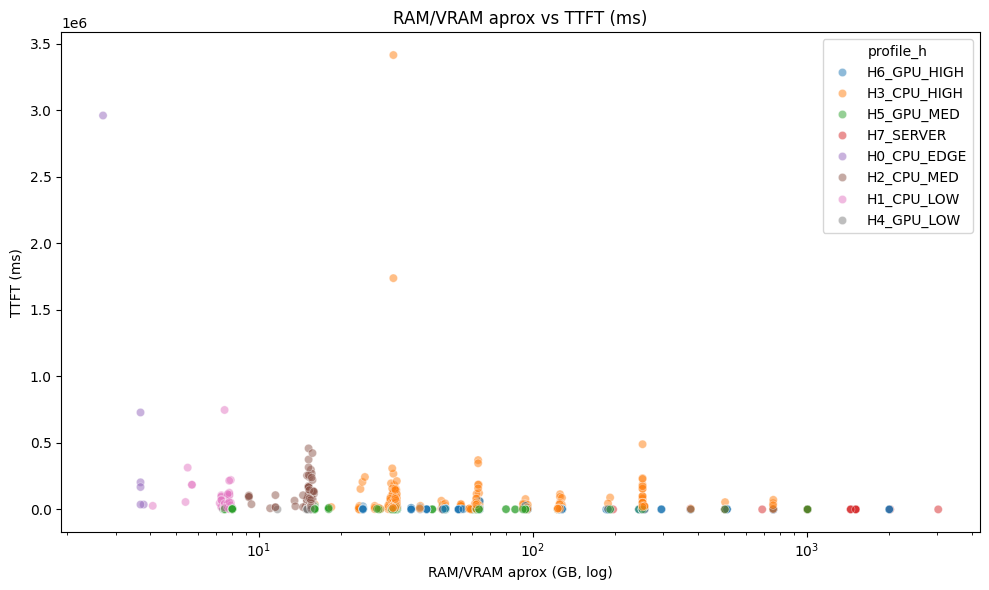

In [6]:
# =========================
# Visualizaciones basicas (opcionales)
# =========================

import matplotlib.pyplot as plt

try:
    import seaborn as sns
    has_seaborn = True
except Exception:
    has_seaborn = False

# 1) #runs por perfil
plt.figure(figsize=(10,4))
order = ["H0_CPU_EDGE", "H1_CPU_LOW", "H2_CPU_MED", "H3_CPU_HIGH", "H4_GPU_LOW", "H5_GPU_MED", "H6_GPU_HIGH", "H7_SERVER"]
if has_seaborn:
    sns.barplot(data=coverage, x="profile_h", y="n_runs", order=order)
else:
    plt.bar(range(len(order)), coverage.set_index("profile_h").reindex(order, fill_value=0)["n_runs"].values)
    plt.xticks(range(len(order)), order, rotation=45, ha="right")
plt.title("# de corridas por perfil H0-H7")
plt.tight_layout()
plt.show()

# 2) Scatter RAM/VRAM vs TTFT (si hay datos)
plot_df = runs.copy()
# Asegurar que hay columna para scatter
plot_df["ram_or_vram"] = plot_df["ram_gb"].combine_first(plot_df["memory_gb"])

plt.figure(figsize=(10,6))
if has_seaborn:
    sns.scatterplot(data=plot_df, x="ram_or_vram", y="avg_ttft_ms", hue="profile_h", alpha=0.5)
else:
    # fallback simple
    for prof, sub in plot_df.groupby("profile_h"):
        plt.scatter(sub["ram_or_vram"], sub["avg_ttft_ms"], alpha=0.4, label=prof, s=10)
    plt.legend(loc="best")
plt.xscale("log")
plt.title("RAM/VRAM aprox vs TTFT (ms)")
plt.xlabel("RAM/VRAM aprox (GB, log)")
plt.ylabel("TTFT (ms)")
plt.tight_layout()
plt.show()


In [7]:
# =========================
# Diversidad de modelos por perfil
# =========================
model_div = (
    runs.groupby("profile_h")
    .agg(n_models=("model_name","nunique"))
    .reset_index()
)
display(model_div)


,profile_h,n_models
0,H0_CPU_EDGE,1
1,H1_CPU_LOW,8
2,H2_CPU_MED,22
3,H3_CPU_HIGH,44
4,H4_GPU_LOW,23
5,H5_GPU_MED,38
6,H6_GPU_HIGH,49
7,H7_SERVER,3


In [8]:
# =========================
# Export de resultados
# =========================

runs_out = runs.copy()

csv_path = OUT_DIR / "localscore_runs_labeled_H1-H6.csv"
runs_out.to_csv(csv_path, index=False)
print("Export CSV:", csv_path)

# Parquet (si pyarrow esta disponible)
parquet_path = OUT_DIR / "localscore_runs_labeled_H1-H6.parquet"
try:
    runs_out.to_parquet(parquet_path, index=False)
    print("Export Parquet:", parquet_path)
except Exception as e:
    print("No se pudo exportar Parquet.")
    print("Error:", e)

coverage_path = OUT_DIR / "localscore_profile_coverage_H1-H6.csv"
perf_path = OUT_DIR / "localscore_profile_performance_summary_H1-H6.csv"
modeldiv_path = OUT_DIR / "localscore_profile_model_diversity_H1-H6.csv"

coverage.to_csv(coverage_path, index=False)
perf_summary.to_csv(perf_path, index=False)
model_div.to_csv(modeldiv_path, index=False)

print("Export tablas:")
print(" -", coverage_path)
print(" -", perf_path)
print(" -", modeldiv_path)


Export CSV: ../data/processed/localscore_runs_labeled_H1-H6.csv
No se pudo exportar Parquet.
Error: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.
Export tablas:
 - ../data/processed/localscore_profile_coverage_H1-H6.csv
 - ../data/processed/localscore_profile_performance_summary_H1-H6.csv
 - ../data/processed/localscore_profile_model_diversity_H1-H6.csv


In [9]:
# =========================
# Consistencia vs notebook existente
# =========================
# El notebook exploracion_localscore trabaja con el resumen agregado:
#   accelerator_model_performance_scores
# Este bloque verifica (a nivel agregacion) que el ratio CPU vs GPU y los rangos de memoria
# sean coherentes con el etiquetado a nivel corrida.

agg = pd.read_sql_query("SELECT * FROM accelerator_model_performance_scores", conn)
print("agg shape:", agg.shape)

# Ratio CPU vs GPU (agregado)
agg_cpu_gpu = (
    agg.groupby("accelerator_type")
    .agg(n_combinaciones=("accelerator_id","count"),
         avg_gen_tps_media=("avg_gen_tps","mean"),
         avg_ttft_media=("avg_ttft","mean")
        )
    .reset_index()
)
display(agg_cpu_gpu)

# Ratio CPU vs GPU (run-level)
runs_cpu_gpu = (
    runs.groupby("accelerator_type")
    .agg(n_runs=("benchmark_run_id","count"))
    .reset_index()
)
display(runs_cpu_gpu)

print("Chequeo rapido:")
print("- agg_cpu_gpu: n_combinaciones CPU vs GPU")
print("- runs_cpu_gpu: n_runs CPU vs GPU")

# Cierra conexion
conn.close()
print("Conexion cerrada")


agg shape: (1094, 12)


,accelerator_type,n_combinaciones,avg_gen_tps_media,avg_ttft_media
0,CPU,570,43.096150,61602.669948
1,GPU,524,72.523342,2627.674857


,accelerator_type,n_runs
0,CPU,626
1,GPU,930


Chequeo rapido:
- agg_cpu_gpu: n_combinaciones CPU vs GPU
- runs_cpu_gpu: n_runs CPU vs GPU
Conexion cerrada


## Gráfico 1 — Distribución de la muestra por perfil de hardware

Histograma de barras H1–H6 + Others con:
- colores agrupados por tipo (CPU-only, GPU dedicada, Servidor, Sin clasificar)
- anotaciones de count y % sobre cada barra
- etiquetas descriptivas en el eje X
- guardado en `reports/figures/fig01_hardware_profiles_distribution.png`

Guardado: ../reports/figures/fig01_hardware_profiles_distribution.png


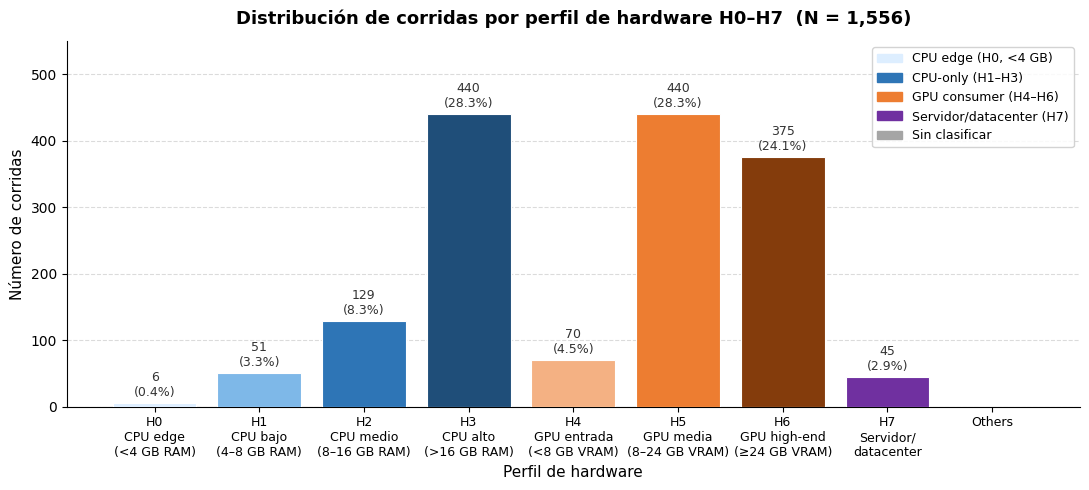

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Orden canónico y etiquetas de eje ────────────────────────────────────────
PROFILE_ORDER = [
    "H0_CPU_EDGE",
    "H1_CPU_LOW",
    "H2_CPU_MED",
    "H3_CPU_HIGH",
    "H4_GPU_LOW",
    "H5_GPU_MED",
    "H6_GPU_HIGH",
    "H7_SERVER",
    "UNKNOWN",
]

PROFILE_LABELS = {
    "H0_CPU_EDGE":  "H0\nCPU edge\n(<4 GB RAM)",
    "H1_CPU_LOW":   "H1\nCPU bajo\n(4–8 GB RAM)",
    "H2_CPU_MED":   "H2\nCPU medio\n(8–16 GB RAM)",
    "H3_CPU_HIGH":  "H3\nCPU alto\n(>16 GB RAM)",
    "H4_GPU_LOW":   "H4\nGPU entrada\n(<8 GB VRAM)",
    "H5_GPU_MED":   "H5\nGPU media\n(8–24 GB VRAM)",
    "H6_GPU_HIGH":  "H6\nGPU high-end\n(≥24 GB VRAM)",
    "H7_SERVER":    "H7\nServidor/\ndatacenter",
    "UNKNOWN":      "Others",
}

PROFILE_COLORS = {
    "H0_CPU_EDGE":  "#DDEEFF",  # azul muy claro  — CPU edge
    "H1_CPU_LOW":   "#7EB8E8",  # azul claro      — CPU bajo
    "H2_CPU_MED":   "#2E75B6",  # azul medio      — CPU medio
    "H3_CPU_HIGH":  "#1F4E79",  # azul oscuro     — CPU alto
    "H4_GPU_LOW":   "#F4B183",  # naranja claro   — GPU entrada
    "H5_GPU_MED":   "#ED7D31",  # naranja         — GPU media
    "H6_GPU_HIGH":  "#843C0C",  # naranja oscuro  — GPU high-end
    "H7_SERVER":    "#7030A0",  # violeta         — Servidor
    "UNKNOWN":      "#A5A5A5",  # gris            — Sin clasificar
}

# ── Datos ────────────────────────────────────────────────────────────────────
plot_data = (
    coverage
    .set_index("profile_h")
    .reindex(PROFILE_ORDER, fill_value=0)
    .reset_index()
)
plot_data["label"] = plot_data["profile_h"].map(PROFILE_LABELS)
plot_data["color"] = plot_data["profile_h"].map(PROFILE_COLORS)
total = plot_data["n_runs"].sum()
plot_data["pct"] = plot_data["n_runs"] / total * 100

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    range(len(plot_data)),
    plot_data["n_runs"],
    color=plot_data["color"],
    edgecolor="white",
    linewidth=0.8,
    zorder=3,
)

# Anotaciones: count + %
for bar, row in zip(bars, plot_data.itertuples()):
    if row.n_runs > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 6,
            f"{row.n_runs:,}\n({row.pct:.1f}%)",
            ha="center", va="bottom", fontsize=9, color="#333333",
        )

ax.set_xticks(range(len(plot_data)))
ax.set_xticklabels(plot_data["label"], fontsize=9)
ax.set_ylabel("Número de corridas", fontsize=11)
ax.set_xlabel("Perfil de hardware", fontsize=11)
ax.set_title(
    f"Distribución de corridas por perfil de hardware H0–H7  (N = {total:,})",
    fontsize=13, fontweight="bold", pad=12,
)
ax.set_ylim(0, plot_data["n_runs"].max() * 1.25)
ax.yaxis.grid(True, linestyle="--", alpha=0.45, zorder=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Leyenda por tipo
cpu_patch  = mpatches.Patch(color="#DDEEFF", label="CPU edge (H0, <4 GB)")
cpu2_patch = mpatches.Patch(color="#2E75B6", label="CPU-only (H1–H3)")
gpu_patch  = mpatches.Patch(color="#ED7D31", label="GPU consumer (H4–H6)")
srv_patch  = mpatches.Patch(color="#7030A0", label="Servidor/datacenter (H7)")
oth_patch  = mpatches.Patch(color="#A5A5A5", label="Sin clasificar")
ax.legend(
    handles=[cpu_patch, cpu2_patch, gpu_patch, srv_patch, oth_patch],
    loc="upper right", fontsize=9, framealpha=0.85,
)

plt.tight_layout()

# ── Guardar ──────────────────────────────────────────────────────────────────
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig_path = FIG_DIR / "fig01_hardware_profiles_distribution.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Guardado: {fig_path}")
plt.show()
